# Intelligent Policy Compliance Checker — Mid-Term Progress
**Goal:** read an organisation's policies and procedure documents and decide, for every rule, whether the documented procedure is **Compliant**, **Non-compliant**, or **Not addressed** — and show the evidence.

This notebook walks through the work done so far, top to bottom. Every cell can be re-run.

In [1]:
import os, sys, json
import pandas as pd
from IPython.display import Image, HTML, display
sys.path.insert(0, 'src')
pd.set_option('display.max_colwidth', 120)

## 1. Dataset — ContractNLI (Stanford NLP, 2021)
607 real legal agreements (NDAs). For **17 rules**, lawyers marked each document as following the rule, breaking it, or not mentioning it, and highlighted the evidence clauses.

| Dataset label | Our label |
|---|---|
| Entailment | Compliant |
| Contradiction | Non-compliant |
| NotMentioned | Not addressed |

In [2]:
!python src/prepare_data.py

train:  423 documents,  32895 clauses,  7191 (document, rule) pairs
dev  :   61 documents,   5102 clauses,  1037 (document, rule) pairs
test :  123 documents,  10061 clauses,  2091 (document, rule) pairs

Saved processed tables to C:\yash\college\sem V\ML\ML LAB\policy_compliance_checker\data\processed


In [3]:
rules = pd.read_csv('data/processed/rules.csv'); rules

,rule_id,rule_name,rule_text
0,nda-1,Explicit identification,All Confidential Information shall be expressly identified by the Disclosing Party.
1,nda-2,None-inclusion of non-technical information,Confidential Information shall only include technical information.
2,nda-3,Inclusion of verbally conveyed information,Confidential Information may include verbally conveyed information.
3,nda-4,Limited use,Receiving Party shall not use any Confidential Information for any purpose other than the purposes stated in Agreement.
4,nda-5,Sharing with employees,Receiving Party may share some Confidential Information with some of Receiving Party's employees.
5,nda-7,Sharing with third-parties,"Receiving Party may share some Confidential Information with some third-parties (including consultants, agents and p..."
6,nda-8,Notice on compelled disclosure,"Receiving Party shall notify Disclosing Party in case Receiving Party is required by law, regulation or judicial pro..."
7,nda-10,Confidentiality of Agreement,Receiving Party shall not disclose the fact that Agreement was agreed or negotiated.
8,nda-11,No reverse engineering,Receiving Party shall not reverse engineer any objects which embody Disclosing Party's Confidential Information.
9,nda-12,Permissible development of similar information,Receiving Party may independently develop information similar to Confidential Information.


In [4]:
pairs = pd.read_csv('data/processed/pairs_train.csv')
pairs[pairs.label != 'NOT_ADDRESSED'][['doc_id','rule_id','label','evidence_text']].head(5)

,doc_id,rule_id,label,evidence_text
1,34,nda-16,COMPLIANT,"5. All Confidential Information in any form and any medium, including all copies thereof, disclosed to the Recipient..."
2,34,nda-15,COMPLIANT,"4. Nothing in this Agreement is to be construed as granting the Recipient, by implication or otherwise, any right wh..."
3,34,nda-10,COMPLIANT,11. The Recipient shall not advertise or otherwise make public the fact that it has a confidential relationship with...
5,34,nda-1,COMPLIANT,"1. “Confidential Information”, whenever used in this Agreement, shall mean any data, document, specification and oth..."
6,34,nda-19,COMPLIANT,Either Party may terminate the working relationship contemplated by this Agreement by providing written notice to th...


## 2. Exploratory Data Analysis

In [5]:
!python src/eda.py

                            metric value
                         documents   607
        rules checked per document    17
            (document, rule) pairs 10319
                     total clauses 48058
       median clauses per document    71
                   compliant pairs  5017
               non-compliant pairs  1156
               not-addressed pairs  4146
 avg evidence clauses per decision  1.94
avg % of document that is evidence  2.7%

Per-rule violation rate (top 5):
rule_name
None-inclusion of non-technical information    72.7%
Permissible post-agreement possession          38.9%
Explicit identification                        26.0%
Sharing with third-parties                     24.7%
Permissible copy                               18.0%

Charts saved to C:\yash\college\sem V\ML\ML LAB\policy_compliance_checker\outputs\figures


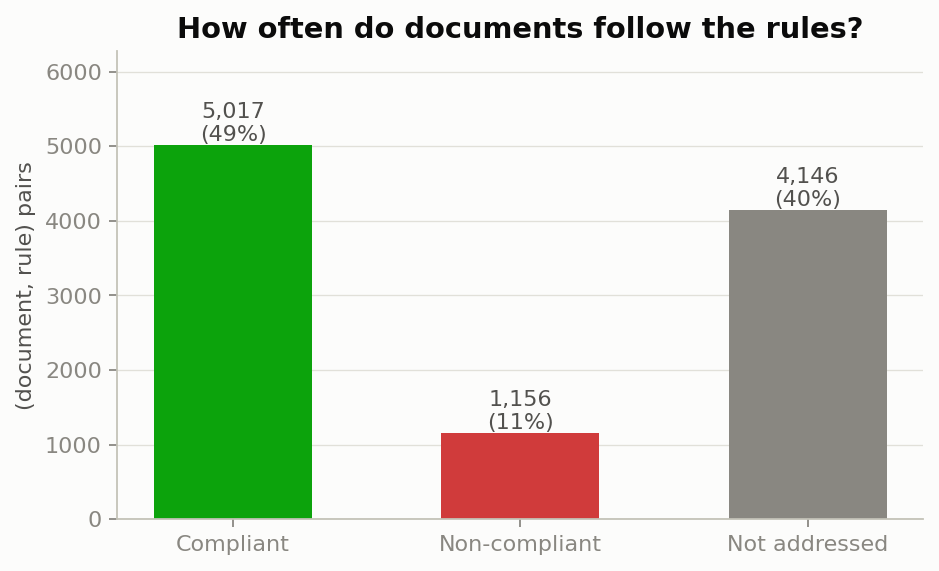

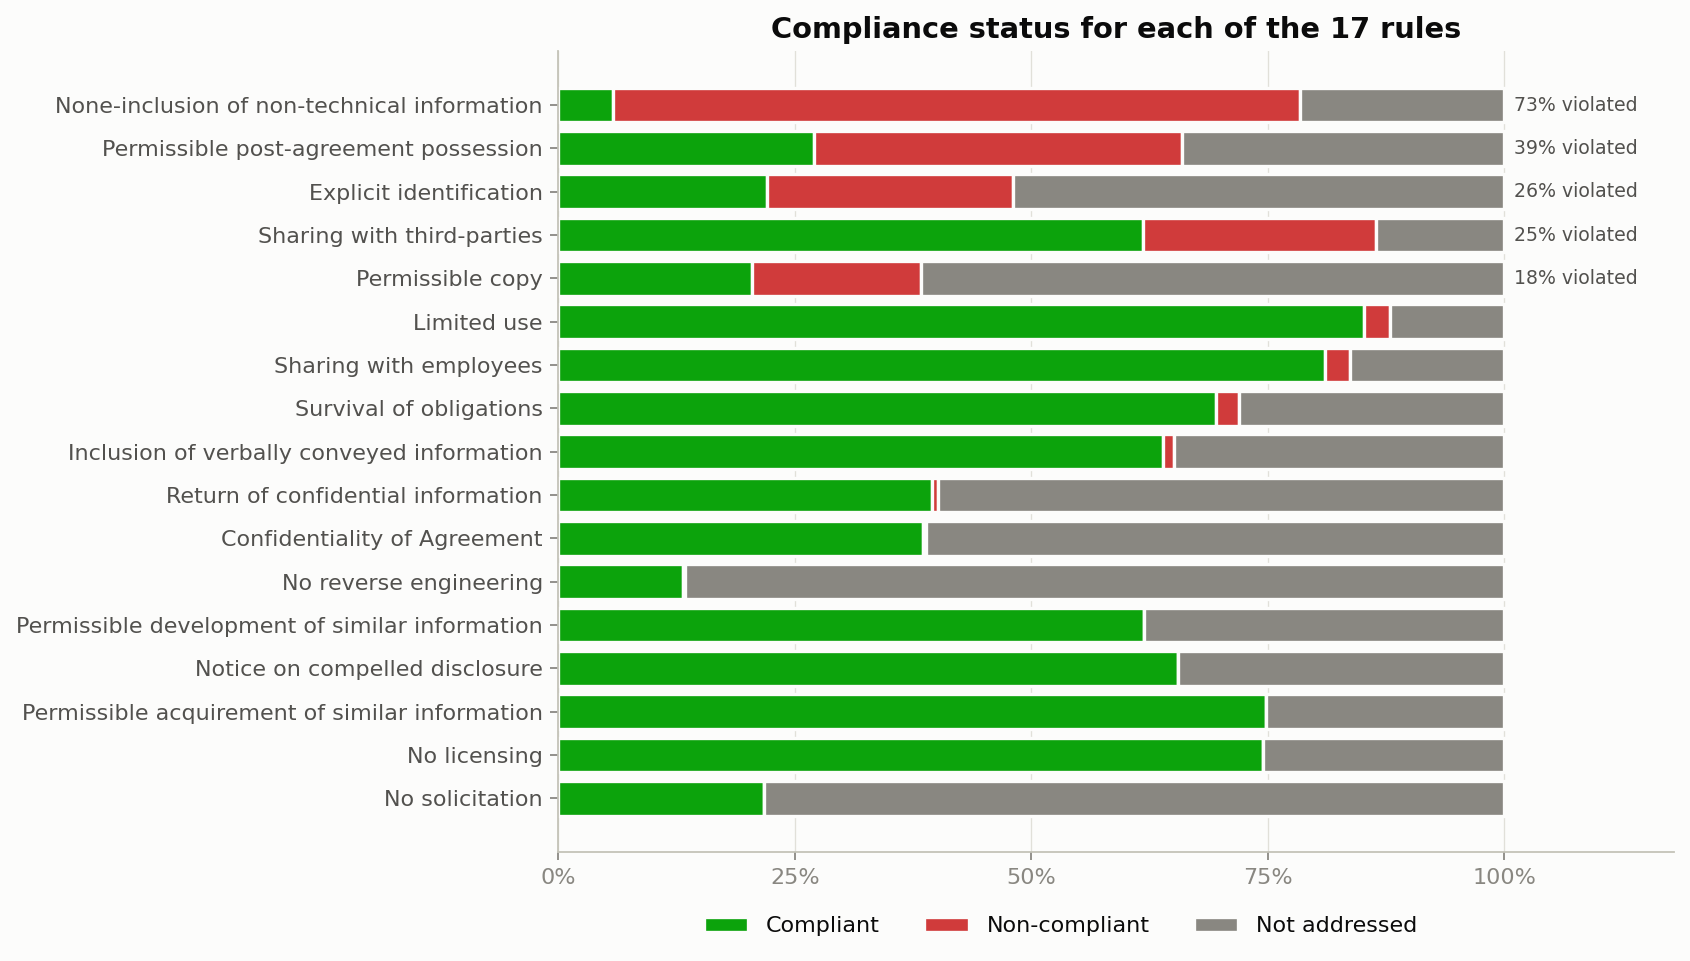

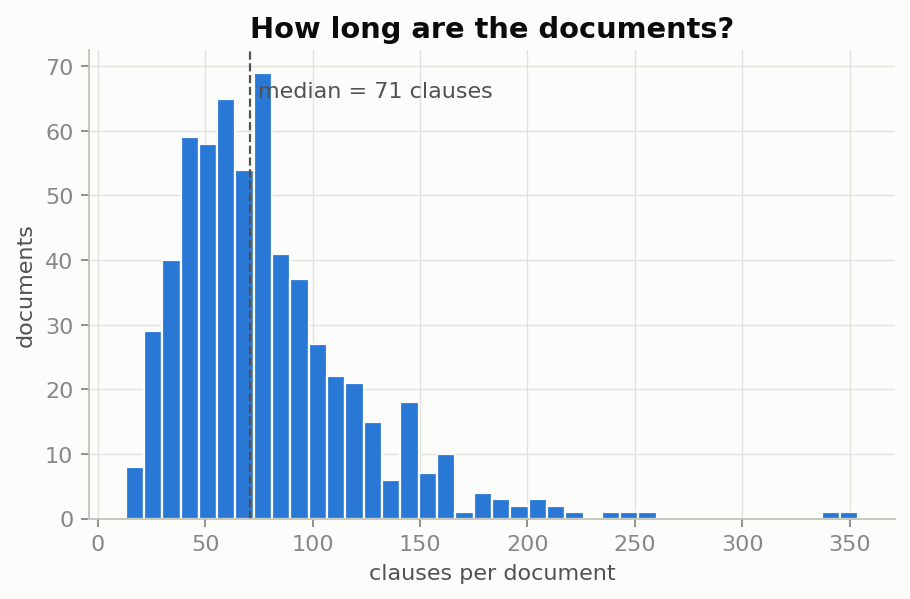

In [6]:
for f in ['01_label_distribution', '02_per_rule_breakdown', '03_document_length']:
    display(Image(f'outputs/figures/{f}.png', width=750))

**Key insight:** the evidence for a rule is only ~2–3% of a document (≈2 clauses out of ≈70). So the system must first **find** the right clauses, then **decide**. That gives our two-stage design:

```
Document ──► [Stage A: Evidence Finder] ──► top-3 clauses ──► [Stage B: Compliance Judge] ──► label + evidence
```

## 3. Machine learning pipeline (trained on 423 docs, tested on 123 unseen docs)

In [7]:
!python src/train_models.py

  stage A trained for nda-1  (Explicit identification)
  stage A trained for nda-2  (None-inclusion of non-technical information)
  stage A trained for nda-3  (Inclusion of verbally conveyed information)
  stage A trained for nda-4  (Limited use)
  stage A trained for nda-5  (Sharing with employees)
  stage A trained for nda-7  (Sharing with third-parties)
  stage A trained for nda-8  (Notice on compelled disclosure)
  stage A trained for nda-10 (Confidentiality of Agreement)
  stage A trained for nda-11 (No reverse engineering)
  stage A trained for nda-12 (Permissible development of similar information)
  stage A trained for nda-13 (Permissible acquirement of similar information)
  stage A trained for nda-15 (No licensing)
  stage A trained for nda-16 (Return of confidential information)
  stage A trained for nda-17 (Permissible copy)
  stage A trained for nda-18 (No solicitation)
  stage A trained for nda-19 (Survival of obligations)
  stage A trained for nda-20 (Permissible post-ag

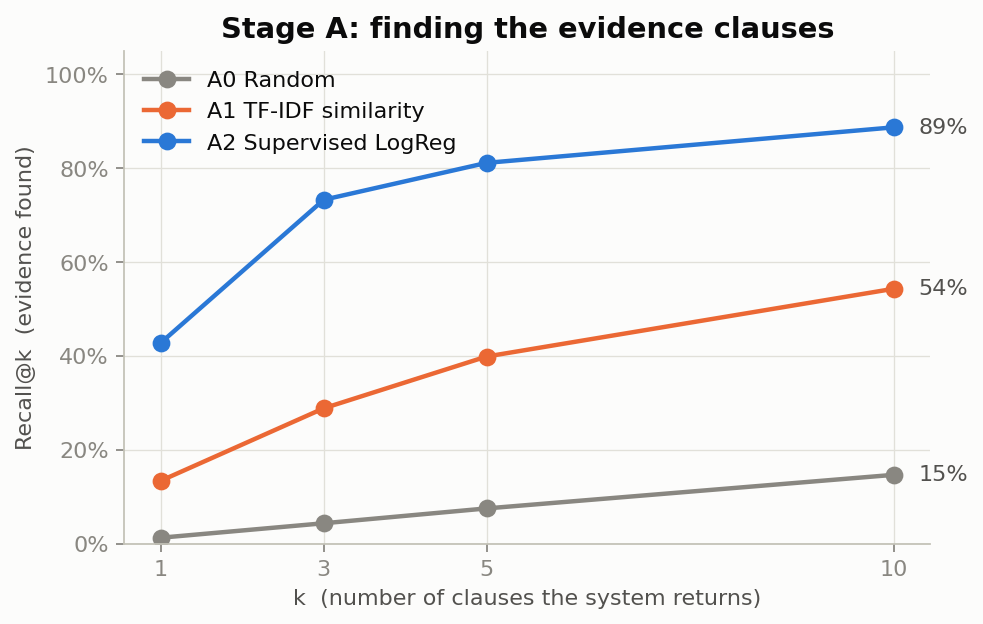

,Recall@1,Recall@3,Recall@5,Recall@10
A0 Random,1.2%,4.3%,7.5%,14.6%
A1 TF-IDF similarity,13.4%,28.8%,39.9%,54.3%
A2 Supervised LogReg,42.8%,73.3%,81.1%,88.7%


In [8]:
display(Image('outputs/figures/04_stageA_recall.png', width=650))
pd.read_csv('outputs/stageA_retrieval_recall.csv', index_col=0).style.format('{:.1%}')

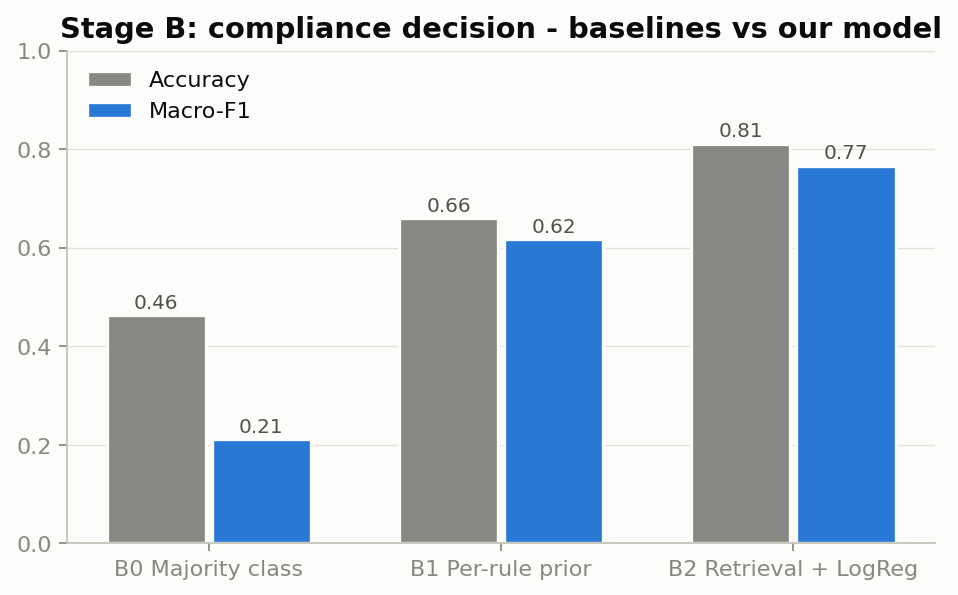

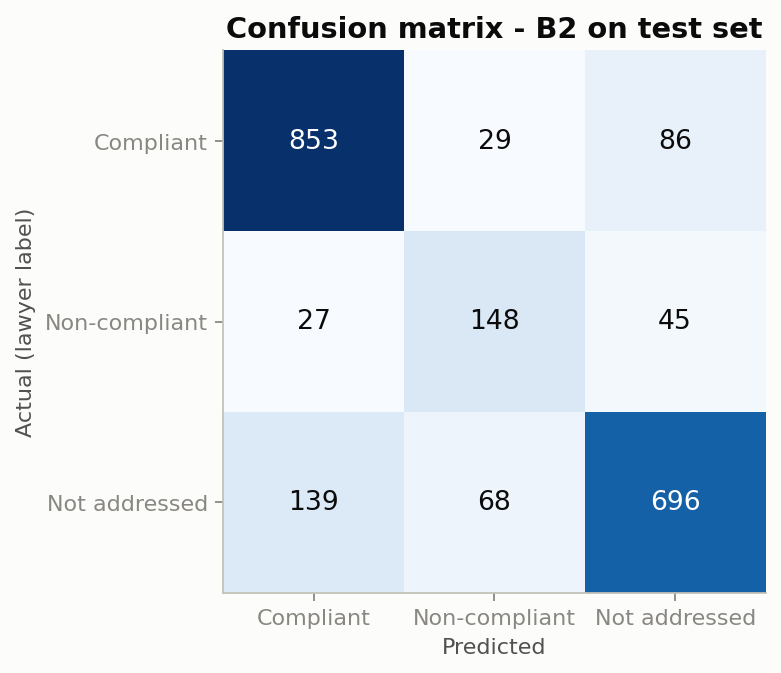

,accuracy,macro_F1,F1_Compliant,F1_Non-compliant,F1_Not addressed
model,,,,,
B0 Majority class,0.463,0.211,0.633,0.000,0.000
B1 Per-rule prior,0.659,0.617,0.730,0.506,0.614
B2 Retrieval + LogReg,0.812,0.767,0.859,0.637,0.805


In [9]:
display(Image('outputs/figures/05_stageB_model_comparison.png', width=650))
display(Image('outputs/figures/06_confusion_matrix.png', width=480))
pd.read_csv('outputs/stageB_classification_results.csv', index_col=0).round(3)

## 4. End-to-end demo on a company-style corpus
A fictional company (NovaTech) with **19 policy rules** across 6 areas (Information Security, Employee Privacy, Data Retention, Workplace Safety, Financial Procedures, Access Control) and **5 department procedure documents**. We labelled the correct answer for every rule ourselves (`data/custom/ground_truth.csv`).

In [10]:
!python src/compliance_checker.py

Loaded 19 rules and 37 procedure clauses

OK SEC-01  Non-compliant  sim=0.59  Procedure says "8 characters"; policy requires at least 12 characters.
OK SEC-02  Compliant      sim=0.62  Procedure says "60 days"; policy requires at most 90 days.
OK SEC-03  Non-compliant  sim=0.62  Mandatory rule, but procedure uses weak wording: "optional".
OK SEC-04  Compliant      sim=0.63  Procedure says "4 hours"; policy requires at most 24 hours.
OK PRV-01  Compliant      sim=0.49  Procedure contains a matching requirement with no weakening language.
OK PRV-02  Non-compliant  sim=0.20  Policy forbids this, but the procedure describes doing it without restriction.
OK PRV-03  Not addressed  sim=0.15  No procedure clause is similar enough (best similarity 0.15 < 0.2).
OK RET-01  Compliant      sim=0.64  Procedure says "10 years"; policy requires at least 8 years.
OK RET-02  Non-compliant  sim=0.33  Procedure says "90 days"; policy requires at most 30 days.
XX RET-03  Compliant      sim=0.21  Procedure 

In [11]:
res = pd.read_csv('outputs/compliance_results.csv')
res[['rule_id','rule','prediction','ground_truth','evidence','reason']]

,rule_id,rule,prediction,ground_truth,evidence,reason
0,SEC-01,User passwords must be at least 12 characters long.,NON_COMPLIANT,NON_COMPLIANT,Every user password must have a minimum of 8 characters and include one number.,"Procedure says ""8 characters""; policy requires at least 12 characters."
1,SEC-02,Passwords must be changed at least every 90 days.,COMPLIANT,COMPLIANT,Passwords are automatically set to expire and must be changed every 60 days.,"Procedure says ""60 days""; policy requires at most 90 days."
2,SEC-03,Multi-factor authentication must be enabled for all remote access.,NON_COMPLIANT,NON_COMPLIANT,Multi-factor authentication is optional for VPN users and may be enabled on request.,"Mandatory rule, but procedure uses weak wording: ""optional""."
3,SEC-04,Security incidents must be reported to the security team within 24 hours.,COMPLIANT,COMPLIANT,"Any suspected security incident, such as malware or phishing, must be reported to the security team within 4 hours o...","Procedure says ""4 hours""; policy requires at most 24 hours."
4,PRV-01,Personal data of employees must be encrypted at rest.,COMPLIANT,COMPLIANT,"Employee records, including salary and medical information, are stored in an encrypted database using AES-256 encryp...",Procedure contains a matching requirement with no weakening language.
5,PRV-02,Employee personal data must not be shared with third parties without written consent.,NON_COMPLIANT,NON_COMPLIANT,HR may share employee contact details with insurance partners to send them marketing offers.,"Policy forbids this, but the procedure describes doing it without restriction."
6,PRV-03,A data breach involving personal data must be notified to affected employees within 72 hours.,NOT_ADDRESSED,NOT_ADDRESSED,"Employees must submit expense claims within 60 days of incurring the expense, along with original receipts.",No procedure clause is similar enough (best similarity 0.15 < 0.2).
7,RET-01,Financial records must be retained for at least 8 years.,COMPLIANT,COMPLIANT,"Invoices, ledgers and other financial records are archived and retained for 10 years in the document management system.","Procedure says ""10 years""; policy requires at least 8 years."
8,RET-02,CCTV footage must not be kept for more than 30 days.,NON_COMPLIANT,NON_COMPLIANT,Footage from CCTV cameras at all entrances is stored on the local recorder for 90 days and then overwritten.,"Procedure says ""90 days""; policy requires at most 30 days."
9,RET-03,Backups must be tested for restoration every quarter.,COMPLIANT,NOT_ADDRESSED,Backups of all servers are taken every night and stored at the secondary data centre.,Procedure contains a matching requirement with no weakening language.


In [12]:
display(HTML(open('outputs/compliance_report.html', encoding='utf-8').read()))

## 5. Limitations found & next steps (post mid-term)
- **Synonyms:** ACC-03 missed — the procedure says *"common login"*, the rule says *"shared or generic accounts"*. TF-IDF matches words, not meaning → add **sentence embeddings** (e.g. Sentence-BERT).
- **Partial coverage:** RET-03 — backups are documented but *restoration testing* is not. The checker found the topic and assumed compliance → add a **transformer NLI model** (e.g. fine-tuned DeBERTa on ContractNLI).
- Non-compliant class is hardest (F1 0.64) because it is rarest (11% of data) → class balancing / data augmentation.
- Accept **PDF / DOCX** input and build a simple web UI to upload documents.